# Logistic Regression

Binary classifier: `p(y=1|x) = sigmoid(Xw + b)`, trained by batch gradient descent minimizing binary cross-entropy.

## Usage

```python
# (the class is defined in the Implementation section below)

model = LogisticRegression(lr=0.1, n_iters=2000).fit(X, y)
probs = model.predict_proba(X_test)
labels = model.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


class LogisticRegression:
    """Binary logistic regression trained by batch gradient descent on BCE loss."""

    def __init__(self, lr=0.1, n_iters=2000):
        self.lr = lr
        self.n_iters = n_iters
        self.weights = None
        self.bias = 0.0

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for _ in range(self.n_iters):
            z = X @ self.weights + self.bias
            y_pred = _sigmoid(z)
            error = y_pred - y
            grad_w = (1 / n_samples) * (X.T @ error)
            grad_b = (1 / n_samples) * np.sum(error)
            self.weights -= self.lr * grad_w
            self.bias -= self.lr * grad_b
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        return _sigmoid(X @ self.weights + self.bias)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

## See it work

### 1. The sigmoid turns a score into a probability

Logistic regression computes a linear score `z = Xw + b` and squashes it with `σ(z) = 1/(1 + e⁻ᶻ)` into (0, 1). The decision boundary is where `σ(z) = 0.5`, i.e. `z = 0`. One feature, so we can see the S-curve:

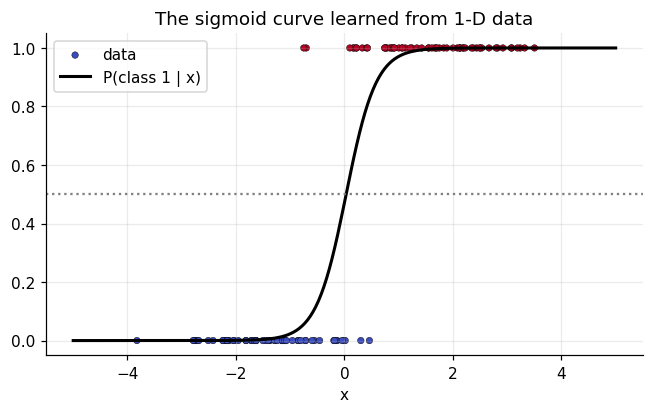

In [3]:
rng = np.random.default_rng(0)
x = np.concatenate([rng.normal(-1.5, 1.0, 60), rng.normal(1.5, 1.0, 60)]); y = np.array([0] * 60 + [1] * 60)
m = LogisticRegression(lr=0.1, n_iters=3000).fit(x[:, None], y)
xs = np.linspace(-5, 5, 200)
plt.figure(figsize=(7, 3.8))
plt.scatter(x, y, c=y, cmap="coolwarm", s=18, edgecolor="k", linewidth=0.3, label="data")
plt.plot(xs, m.predict_proba(xs[:, None]), "k", lw=2, label="P(class 1 | x)"); plt.axhline(0.5, color="gray", ls=":")
plt.xlabel("x"); plt.legend(); plt.title("The sigmoid curve learned from 1-D data"); plt.show()

### 2. A probability map in 2-D

Two overlapping blobs. The colour is `P(class 1 | x)`; the white line (`0.5`) is a straight line, because the score is linear. Points near it are uncertain, far away they are confident.

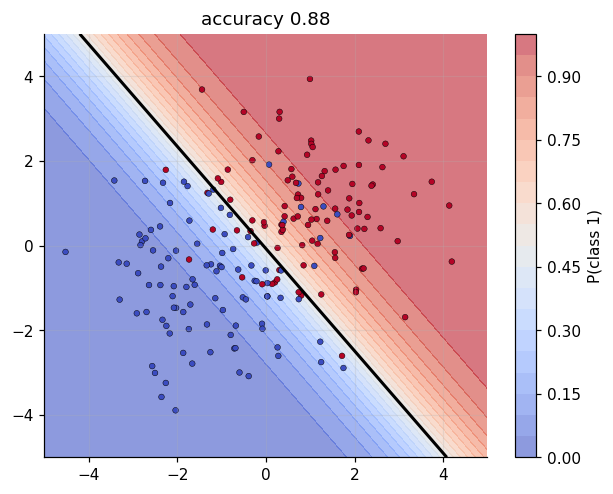

In [4]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=200, centers=[[-1.2, -1], [1.2, 1]], cluster_std=1.3, random_state=0)
m = LogisticRegression(lr=0.1, n_iters=3000).fit(X, y)
gx, gy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-5, 5, 200))
P = m.predict_proba(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
plt.figure(figsize=(6.5, 5))
plt.contourf(gx, gy, P, levels=20, cmap="coolwarm", alpha=0.6); plt.colorbar(label="P(class 1)")
plt.contour(gx, gy, P, levels=[0.5], colors="k", linewidths=2)
plt.scatter(*X.T, c=y, cmap="coolwarm", s=14, edgecolor="k", linewidth=0.3); plt.title(f"accuracy {(m.predict(X) == y).mean():.2f}"); plt.show()

### 3. Moving the threshold trades off error types

`predict` uses 0.5, but you can pick another cut. Lower it and you catch more positives (higher recall) at the price of more false alarms (lower precision). The right threshold depends on what the mistakes cost.

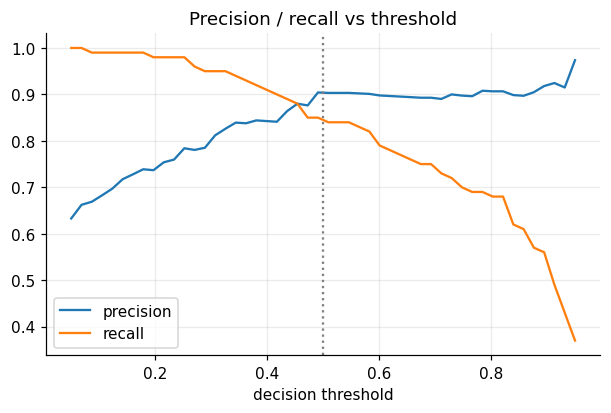

In [5]:
p = m.predict_proba(X)
thr = np.linspace(0.05, 0.95, 50)
prec = [((p >= t) & (y == 1)).sum() / max((p >= t).sum(), 1) for t in thr]
rec = [((p >= t) & (y == 1)).sum() / (y == 1).sum() for t in thr]
plt.figure(figsize=(6.5, 3.8)); plt.plot(thr, prec, label="precision"); plt.plot(thr, rec, label="recall")
plt.axvline(0.5, color="gray", ls=":"); plt.xlabel("decision threshold"); plt.legend(); plt.title("Precision / recall vs threshold"); plt.show()

### 4. The limit: a straight boundary only

On concentric circles no line separates the classes, and logistic regression cannot do better than guessing. Adding squared features (`04_polynomial_regression`'s trick) or using a kernel / neural net fixes it.

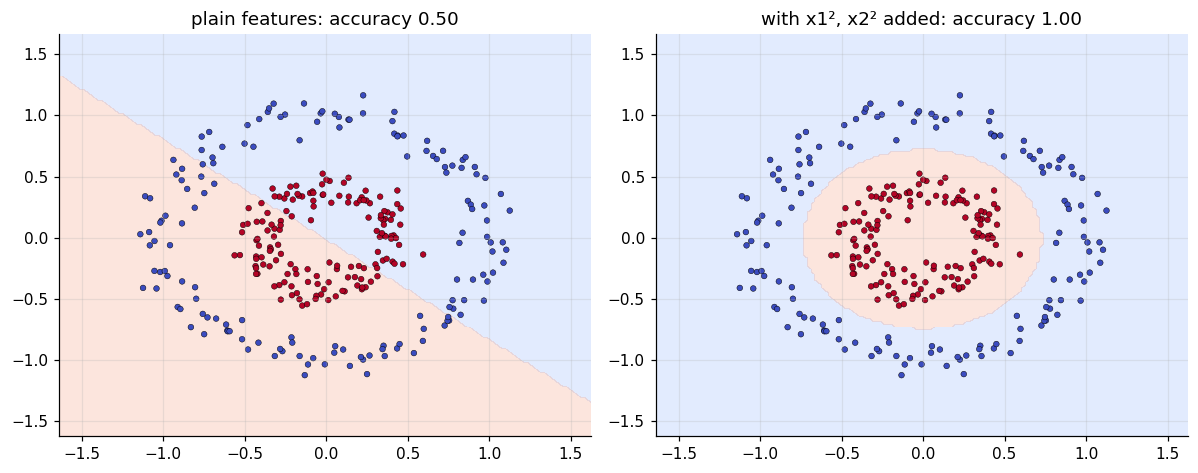

In [6]:
from sklearn.datasets import make_circles

Xc, yc = make_circles(n_samples=300, factor=0.4, noise=0.08, random_state=0)
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)
lin = LogisticRegression().fit(Xc, yc)
sq = LogisticRegression(lr=0.5, n_iters=3000).fit(np.c_[Xc, Xc ** 2], yc)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.4))
class Squared:                       # wrap the model so plot_boundary can feed it 2-D points
    predict = staticmethod(lambda P: sq.predict(np.c_[P, P ** 2]))
plot_boundary(a, lin, Xc, yc); a.set_title(f"plain features: accuracy {(lin.predict(Xc) == yc).mean():.2f}")
plot_boundary(b, Squared, Xc, yc); b.set_title(f"with x1², x2² added: accuracy {(sq.predict(np.c_[Xc, Xc ** 2]) == yc).mean():.2f}")
plt.tight_layout(); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [7]:
import numpy as np
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)
class0 = rng.normal(loc=-2, scale=1.2, size=(200, 2))
class1 = rng.normal(loc=2, scale=1.2, size=(200, 2))
X = np.vstack([class0, class1])
y = np.array([0] * 200 + [1] * 200)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

ours = LogisticRegression(lr=0.1, n_iters=3000).fit(X_train, y_train)
theirs = SklearnLogisticRegression().fit(X_train, y_train)

acc_ours = (ours.predict(X_test) == y_test).mean()
acc_theirs = (theirs.predict(X_test) == y_test).mean()
print("test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
assert abs(acc_ours - acc_theirs) < 0.05

test accuracy: ours=0.9800 sklearn=0.9800


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [8]:
import numpy as np


def test_sigmoid_bounds():
    assert _sigmoid(0.0) == 0.5
    assert _sigmoid(100) > 0.999
    assert _sigmoid(-100) < 0.001


def test_separable_blobs():
    rng = np.random.default_rng(0)
    class0 = rng.normal(loc=-3, scale=0.5, size=(100, 2))
    class1 = rng.normal(loc=3, scale=0.5, size=(100, 2))
    X = np.vstack([class0, class1])
    y = np.array([0] * 100 + [1] * 100)

    model = LogisticRegression(lr=0.1, n_iters=2000).fit(X, y)
    preds = model.predict(X)
    accuracy = (preds == y).mean()
    assert accuracy > 0.98, accuracy

In [9]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_sigmoid_bounds
PASS test_separable_blobs

all 2 tests passed


## Takeaways

- **Use it when** you want a fast, well-calibrated, interpretable binary classifier: a strong baseline for tabular data. Weights are log-odds: `e^w` is the odds multiplier per unit of a feature.
- **Loss and gradient:** cross-entropy `−mean(y·log p + (1−y)·log(1−p))`, gradient `Xᵀ(p − y)/n`, the same form as linear regression but with `p = σ(Xw + b)`.
- **Pitfalls:** linear boundary only (section 4), needs scaled features for gradient descent, separable data drives weights to infinity without regularisation, and class imbalance means you should tune the threshold (section 3).
- **Multiclass:** `10_softmax_regression`.
- **Interview line:** *"Linear score, sigmoid, cross-entropy; gradient `Xᵀ(p − y)/n`; the boundary is a hyperplane."*